<a href="https://colab.research.google.com/github/AsfandyarFarooqi/learning-log/blob/main/week04_least_squares.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [7]:
measured = np.array([10.02, 9.97, 10.04,10.05])
L_best = measured.mean()
print("best length L =", L_best)
residuals_tape = measured - L_best
print("residuals:", np.round(residuals_tape, 4))
print("sum of squares:", round(np.sum(residuals_tape**2), 5))

best length L = 10.02
residuals: [ 0.   -0.05  0.02  0.03]
sum of squares: 0.0038


In [3]:
for L in [10.00, 10.01, 10.02]:
    total = np.sum((measured - L)**2)
    print("L =", L, "-> sum of squares:", round(total, 5))

L = 10.0 -> sum of squares: 0.0029
L = 10.01 -> sum of squares: 0.0026
L = 10.02 -> sum of squares: 0.0029


10.01


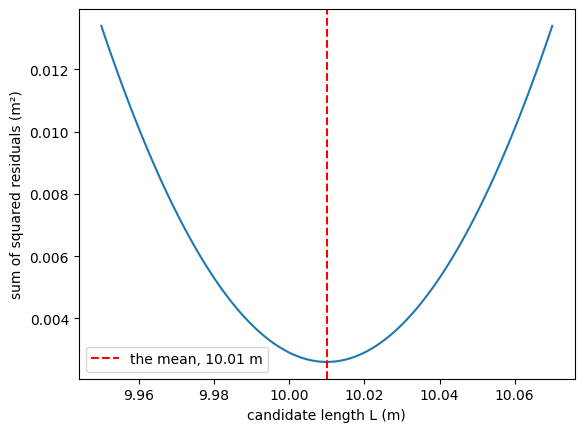

In [6]:
L_values = np.linspace(9.95, 10.07, 121)
totals = []
for L in L_values:
    totals.append(np.sum((measured - L)**2))
print(np.mean(L_values))
plt.plot(L_values, totals)
plt.axvline(10.01, color="red", linestyle="--", label="the mean, 10.01 m")
plt.xlabel("candidate length L (m)")
plt.ylabel("sum of squared residuals (m²)")
plt.legend()
plt.show()

In [18]:
import numpy as np

A = np.array([[ 1, 0],
              [-1, 1],
              [ 0, 1]])
b = np.array([2.0, 1.5, 3.5])
pairs = [[0, 1], [0, 2], [1, 2]]
for rows in pairs:
    print("rows =", rows)
    print("A[rows] =")
    print(A[rows])
    print("b[rows] =", b[rows])
    heights = np.linalg.solve(A[rows], b[rows])
    print("-> h_P, h_Q =", np.round(heights, 4))
    print()

rows = [0, 1]
A[rows] =
[[ 1  0]
 [-1  1]]
b[rows] = [2.  1.5]
-> h_P, h_Q = [2.  3.5]

rows = [0, 2]
A[rows] =
[[1 0]
 [0 1]]
b[rows] = [2.  3.5]
-> h_P, h_Q = [2.  3.5]

rows = [1, 2]
A[rows] =
[[-1  1]
 [ 0  1]]
b[rows] = [1.5 3.5]
-> h_P, h_Q = [2.  3.5]



In [19]:
x_hat, ssr, rank, sv = np.linalg.lstsq(A, b, rcond=None)
print("least-squares h_P, h_Q =", np.round(x_hat, 4))
print("rank of A:", rank)
residuals = b - A @ x_hat
print("residuals:", np.round(residuals, 4))
print("sum of squares:", round(np.sum(residuals**2), 5))
print("lstsq's own sum:", ssr)

least-squares h_P, h_Q = [2.  3.5]
rank of A: 2
residuals: [-0. -0. -0.]
sum of squares: 0.0
lstsq's own sum: [7.88860905e-31]


In [17]:
for rows in pairs:
    heights = np.linalg.solve(A[rows], b[rows])
    r = b - A @ heights
    print("rows", rows, "-> residuals", np.round(r, 4), "-> sum of squares:", round(np.sum(r**2), 5))
print("least squares -> sum of squares:", round(np.sum(residuals**2), 5))

rows [0, 1] -> residuals [0.  0.  0.1] -> sum of squares: 0.01
rows [0, 2] -> residuals [ 0.  -0.1  0. ] -> sum of squares: 0.01
rows [1, 2] -> residuals [-0.1  0.   0. ] -> sum of squares: 0.01
least squares -> sum of squares: 0.00333
